In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

print(os.getcwd())

C:\Users\immek


In [4]:
import pandas as pd

file_path = r"C:\Users\immek\online_retail_II.xlsx"

df1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")

df2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

print("First sheet shape:", df1.shape)
print("Second sheet shape:", df2.shape)

First sheet shape: (525461, 8)
Second sheet shape: (541910, 8)


In [6]:
df = pd.concat([df1, df2], ignore_index=True)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 1067371
Total columns: 8


In [7]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [9]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [10]:
df['Customer ID'].nunique()

5942

In [11]:
df = df.dropna(subset=['Customer ID'])

print("Rows after cleaning:", df.shape[0])
print("Missing Customer IDs:", df['Customer ID'].isnull().sum())

Rows after cleaning: 824364
Missing Customer IDs: 0


In [13]:
df = df.dropna(subset=['Customer ID']).copy()

df['Customer ID'] = df['Customer ID'].astype(int)

print("Data cleaning completed!")
print(df['Customer ID'].dtype)

Data cleaning completed!
int64


In [14]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(df['InvoiceDate'].dtype)

datetime64[ns]


In [15]:
df['InvoiceMonth'] = (
    df['InvoiceDate'].dt.to_period('M')
)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,InvoiceMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-12


In [16]:
df['CohortMonth'] = df.groupby('Customer ID')['InvoiceMonth'].transform('min')

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,InvoiceMonth,CohortMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-12,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,2009-12,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-12,2009-12


In [17]:
df[['Customer ID', 'InvoiceMonth', 'CohortMonth']].head(10)

,Customer ID,InvoiceMonth,CohortMonth
0,13085,2009-12,2009-12
1,13085,2009-12,2009-12
2,13085,2009-12,2009-12
3,13085,2009-12,2009-12
4,13085,2009-12,2009-12
5,13085,2009-12,2009-12
6,13085,2009-12,2009-12
7,13085,2009-12,2009-12
8,13085,2009-12,2009-12
9,13085,2009-12,2009-12


In [18]:
df['CohortIndex'] = (
    (df['InvoiceMonth'].dt.year - df['CohortMonth'].dt.year) * 12
    +
    (df['InvoiceMonth'].dt.month - df['CohortMonth'].dt.month)
    + 1
)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,InvoiceMonth,CohortMonth,CohortIndex
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-12,2009-12,1
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12,2009-12,1
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12,2009-12,1
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,2009-12,2009-12,1
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-12,2009-12,1


In [19]:
df[['Customer ID', 'InvoiceMonth', 'CohortMonth', 'CohortIndex']].head(10)

,Customer ID,InvoiceMonth,CohortMonth,CohortIndex
0,13085,2009-12,2009-12,1
1,13085,2009-12,2009-12,1
2,13085,2009-12,2009-12,1
3,13085,2009-12,2009-12,1
4,13085,2009-12,2009-12,1
5,13085,2009-12,2009-12,1
6,13085,2009-12,2009-12,1
7,13085,2009-12,2009-12,1
8,13085,2009-12,2009-12,1
9,13085,2009-12,2009-12,1


In [20]:
cohort_data = df.groupby(
    ['CohortMonth', 'CohortIndex']
)['Customer ID'].nunique()

cohort_data.head(10)

CohortMonth  CohortIndex
2009-12      1              1045
             2               392
             3               358
             4               447
             5               410
             6               408
             7               408
             8               374
             9               355
             10              392
Name: Customer ID, dtype: int64

In [21]:
cohort_table = cohort_data.unstack()

cohort_table

CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,1045.0,392.0,358.0,447.0,410.0,408.0,408.0,374.0,355.0,392.0,...,319.0,273.0,316.0,303.0,287.0,274.0,332.0,319.0,427.0,218.0
2010-01,394.0,86.0,119.0,120.0,110.0,115.0,105.0,91.0,114.0,134.0,...,60.0,86.0,74.0,69.0,73.0,93.0,73.0,88.0,29.0,NaN
2010-02,363.0,109.0,82.0,110.0,93.0,76.0,79.0,103.0,100.0,106.0,...,74.0,67.0,61.0,53.0,85.0,90.0,62.0,23.0,NaN,NaN
2010-03,436.0,95.0,113.0,103.0,100.0,87.0,105.0,130.0,126.0,50.0,...,74.0,76.0,69.0,74.0,89.0,93.0,33.0,NaN,NaN,NaN
2010-04,291.0,67.0,58.0,47.0,54.0,67.0,79.0,76.0,33.0,34.0,...,43.0,41.0,41.0,50.0,61.0,19.0,NaN,NaN,NaN,NaN
2010-05,254.0,49.0,45.0,49.0,48.0,66.0,56.0,33.0,17.0,22.0,...,33.0,36.0,42.0,40.0,12.0,NaN,NaN,NaN,NaN,NaN
2010-06,269.0,58.0,53.0,55.0,62.0,76.0,35.0,25.0,22.0,32.0,...,33.0,37.0,55.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,183.0,38.0,37.0,52.0,55.0,28.0,21.0,28.0,26.0,22.0,...,32.0,45.0,17.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,158.0,39.0,50.0,51.0,29.0,21.0,16.0,22.0,23.0,21.0,...,32.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
cohort_sizes = cohort_table.iloc[:, 0]

retention_table = cohort_table.divide(cohort_sizes, axis=0) * 100

retention_table

CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,37.511962,34.258373,42.775120,39.234450,39.043062,39.043062,35.789474,33.971292,37.511962,...,30.526316,26.124402,30.239234,28.995215,27.464115,26.220096,31.770335,30.526316,40.861244,20.861244
2010-01,100.0,21.827411,30.203046,30.456853,27.918782,29.187817,26.649746,23.096447,28.934010,34.010152,...,15.228426,21.827411,18.781726,17.512690,18.527919,23.604061,18.527919,22.335025,7.360406,NaN
2010-02,100.0,30.027548,22.589532,30.303030,25.619835,20.936639,21.763085,28.374656,27.548209,29.201102,...,20.385675,18.457300,16.804408,14.600551,23.415978,24.793388,17.079890,6.336088,NaN,NaN
2010-03,100.0,21.788991,25.917431,23.623853,22.935780,19.954128,24.082569,29.816514,28.899083,11.467890,...,16.972477,17.431193,15.825688,16.972477,20.412844,21.330275,7.568807,NaN,NaN,NaN
2010-04,100.0,23.024055,19.931271,16.151203,18.556701,23.024055,27.147766,26.116838,11.340206,11.683849,...,14.776632,14.089347,14.089347,17.182131,20.962199,6.529210,NaN,NaN,NaN,NaN
2010-05,100.0,19.291339,17.716535,19.291339,18.897638,25.984252,22.047244,12.992126,6.692913,8.661417,...,12.992126,14.173228,16.535433,15.748031,4.724409,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,21.561338,19.702602,20.446097,23.048327,28.252788,13.011152,9.293680,8.178439,11.895911,...,12.267658,13.754647,20.446097,5.947955,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,20.765027,20.218579,28.415301,30.054645,15.300546,11.475410,15.300546,14.207650,12.021858,...,17.486339,24.590164,9.289617,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,24.683544,31.645570,32.278481,18.354430,13.291139,10.126582,13.924051,14.556962,13.291139,...,20.253165,6.962025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
retention_table = retention_table.round(2)

retention_table

CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,37.51,34.26,42.78,39.23,39.04,39.04,35.79,33.97,37.51,...,30.53,26.12,30.24,29.00,27.46,26.22,31.77,30.53,40.86,20.86
2010-01,100.0,21.83,30.20,30.46,27.92,29.19,26.65,23.10,28.93,34.01,...,15.23,21.83,18.78,17.51,18.53,23.60,18.53,22.34,7.36,NaN
2010-02,100.0,30.03,22.59,30.30,25.62,20.94,21.76,28.37,27.55,29.20,...,20.39,18.46,16.80,14.60,23.42,24.79,17.08,6.34,NaN,NaN
2010-03,100.0,21.79,25.92,23.62,22.94,19.95,24.08,29.82,28.90,11.47,...,16.97,17.43,15.83,16.97,20.41,21.33,7.57,NaN,NaN,NaN
2010-04,100.0,23.02,19.93,16.15,18.56,23.02,27.15,26.12,11.34,11.68,...,14.78,14.09,14.09,17.18,20.96,6.53,NaN,NaN,NaN,NaN
2010-05,100.0,19.29,17.72,19.29,18.90,25.98,22.05,12.99,6.69,8.66,...,12.99,14.17,16.54,15.75,4.72,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,21.56,19.70,20.45,23.05,28.25,13.01,9.29,8.18,11.90,...,12.27,13.75,20.45,5.95,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,20.77,20.22,28.42,30.05,15.30,11.48,15.30,14.21,12.02,...,17.49,24.59,9.29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,24.68,31.65,32.28,18.35,13.29,10.13,13.92,14.56,13.29,...,20.25,6.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


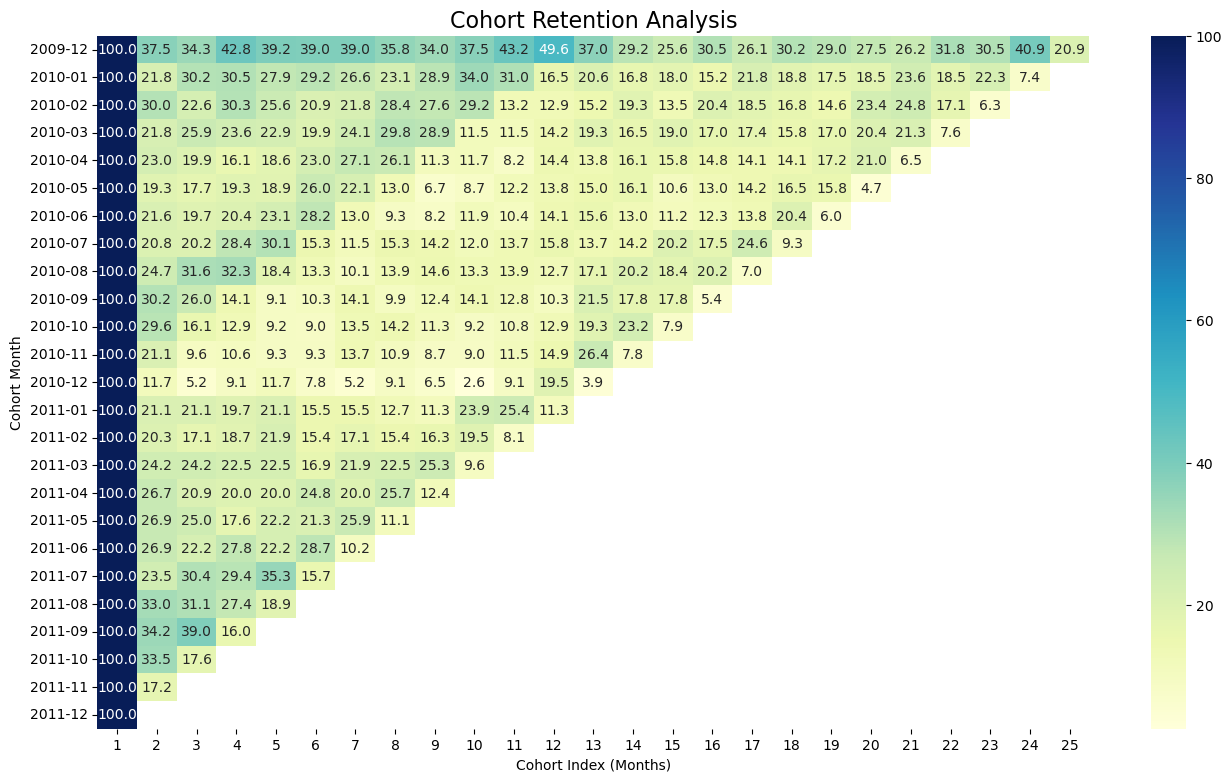

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 9))

sns.heatmap(
    retention_table,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Cohort Retention Analysis', fontsize=16)
plt.xlabel('Cohort Index (Months)')
plt.ylabel('Cohort Month')

plt.show()

In [25]:
print("COHORT RETENTION INSIGHTS")

print("\nAverage Retention by Month:")

print(retention_table.mean().round(2))

print("\nAverage Month 2 Retention:")

print(retention_table[2].mean().round(2), "%")

print("\nAverage Month 3 Retention:")

print(retention_table[3].mean().round(2), "%")

COHORT RETENTION INSIGHTS

Average Retention by Month:
CohortIndex
1     100.00
2      25.02
3      22.95
4      22.25
5      21.34
6      19.48
7      18.54
8      18.12
9      16.38
10     16.10
11     15.67
12     16.64
13     18.32
14     17.52
15     16.18
16     16.63
17     17.49
18     17.75
19     16.71
20     19.25
21     20.49
22     18.74
23     19.74
24     24.11
25     20.86
dtype: float64

Average Month 2 Retention:
25.02 %

Average Month 3 Retention:
22.95 %
